In [1]:
actividades = {
    "A": {"duracion": 4, "pred": [], "recursos": 3},
    "B": {"duracion": 3, "pred": ["A"], "recursos": 2},
    "C": {"duracion": 6, "pred": ["A"], "recursos": 2},
    "D": {"duracion": 2, "pred": ["B"], "recursos": 4},
    "E": {"duracion": 3, "pred": ["C"], "recursos": 2},
    "F": {"duracion": 2, "pred": ["D", "E"], "recursos": 2}
}


def calcular_sucesores(actividades):
    sucesores = {a: [] for a in actividades}

    for a, datos in actividades.items():
        for p in datos["pred"]:
            sucesores[p].append(a)

    return sucesores


def planificar(actividades, max_analistas):

    # -----------------------------------------
    # Validación: ¿alcanzan los analistas?
    # -----------------------------------------

    necesarios = max(
        datos["recursos"]
        for datos in actividades.values()
    )

    if necesarios > max_analistas:

        criticas = [
            a for a, datos in actividades.items()
            if datos["recursos"] > max_analistas
        ]

        faltan = necesarios - max_analistas

        print(
            f"Analistas insuficientes: hay {max_analistas} "
            f"y se necesitan al menos {necesarios}."
        )
        print(f"Faltan {faltan} analista(s).")
        print(
            f"Actividades que no se pueden asignar: "
            f"{', '.join(criticas)}"
        )

        return None, None

    sucesores = calcular_sucesores(actividades)

    # Mayor cantidad de sucesores = mayor prioridad
    prioridad = {
        a: len(sucesores[a])
        for a in actividades
    }

    pendientes = set(actividades.keys())
    ejecutando = {}
    finalizadas = set()

    inicio = {}
    fin = {}

    dia = 1

    while pendientes or ejecutando:

        # -----------------------------------------
        # 1. Finalizan las actividades que
        #    terminan al comienzo de este día
        # -----------------------------------------

        terminan_hoy = [
            a for a, fecha_fin in ejecutando.items()
            if fecha_fin < dia
        ]

        for a in terminan_hoy:
            finalizadas.add(a)
            del ejecutando[a]

        # -----------------------------------------
        # 2. Recursos actualmente ocupados
        # -----------------------------------------

        recursos_usados = sum(
            actividades[a]["recursos"]
            for a in ejecutando
        )

        # -----------------------------------------
        # 3. Actividades disponibles
        # -----------------------------------------

        disponibles = []

        for a in pendientes:

            pred = actividades[a]["pred"]

            if all(p in finalizadas for p in pred):
                disponibles.append(a)

        # -----------------------------------------
        # 4. Ordenamos por prioridad
        # -----------------------------------------

        disponibles.sort(
            key=lambda a: prioridad[a],
            reverse=True
        )

        # -----------------------------------------
        # 5. Asignamos recursos
        # -----------------------------------------

        for a in disponibles:

            recursos = actividades[a]["recursos"]

            if recursos_usados + recursos <= max_analistas:

                inicio[a] = dia

                fin[a] = (
                    dia
                    + actividades[a]["duracion"]
                    - 1
                )

                ejecutando[a] = fin[a]

                recursos_usados += recursos

                pendientes.remove(a)

        dia += 1

    duracion_total = max(fin.values())

    cronograma = {}

    for a in actividades:

        cronograma[a] = {
            "inicio": inicio[a],
            "fin": fin[a],
            "duracion": actividades[a]["duracion"],
            "recursos": actividades[a]["recursos"]
        }

    return cronograma, duracion_total


# -------------------------------------------------
# EJECUCIÓN
# -------------------------------------------------

MAX_ANALISTAS = 6

cronograma, duracion = planificar(
    actividades,
    MAX_ANALISTAS
)

if cronograma:

    print("CRONOGRAMA")
    print("-" * 45)

    for a in sorted(
        cronograma,
        key=lambda x: cronograma[x]["inicio"]
    ):

        c = cronograma[a]

        print(
            f"{a}: "
            f"día {c['inicio']:2d} - "
            f"{c['fin']:2d} | "
            f"{c['recursos']} analistas"
        )

    print("-" * 45)
    print(f"Duración total: {duracion} días")

CRONOGRAMA
---------------------------------------------
A: día  1 -  4 | 3 analistas
B: día  5 -  7 | 2 analistas
C: día  5 - 10 | 2 analistas
D: día  8 -  9 | 4 analistas
E: día 11 - 13 | 2 analistas
F: día 14 - 15 | 2 analistas
---------------------------------------------
Duración total: 15 días


CRONOGRAMA
---------------------------------------------
A: día  1 -  4 | 3 analistas
B: día  5 -  7 | 2 analistas
C: día  5 - 10 | 2 analistas
D: día 11 - 12 | 4 analistas
E: día 13 - 15 | 2 analistas
F: día 16 - 17 | 2 analistas
---------------------------------------------
Duración total: 17 días
Analistas por día: [3, 3, 3, 3, 4, 4, 4, 2, 2, 2, 4, 4, 2, 2, 2, 2, 2]


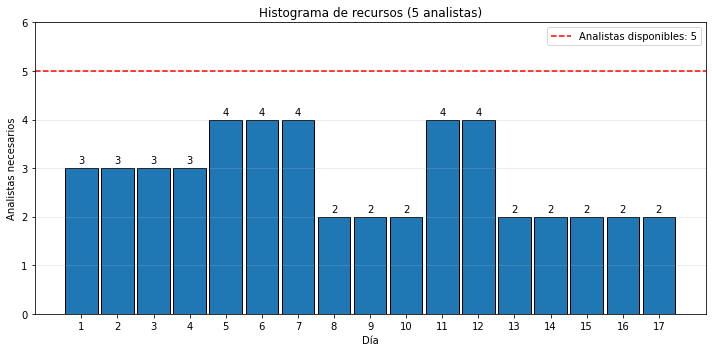


Cantidad óptima de analistas: 6 (duración mínima: 15 días)
Agregar más analistas no reduce la duración.

CRONOGRAMA
---------------------------------------------
A: día  1 -  4 | 3 analistas
B: día  5 -  7 | 2 analistas
C: día  5 - 10 | 2 analistas
D: día  8 -  9 | 4 analistas
E: día 11 - 13 | 2 analistas
F: día 14 - 15 | 2 analistas
---------------------------------------------
Duración total: 15 días
Analistas por día: [3, 3, 3, 3, 4, 4, 4, 6, 6, 2, 2, 2, 2, 2, 2]


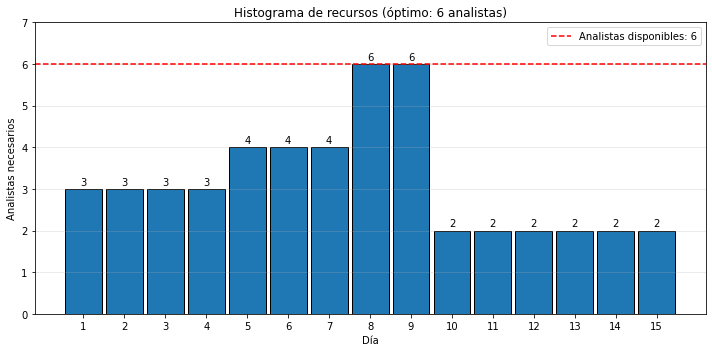

In [2]:
import matplotlib.pyplot as plt

actividades = {
    "A": {"duracion": 4, "pred": [], "recursos": 3},
    "B": {"duracion": 3, "pred": ["A"], "recursos": 2},
    "C": {"duracion": 6, "pred": ["A"], "recursos": 2},
    "D": {"duracion": 2, "pred": ["B"], "recursos": 4},
    "E": {"duracion": 3, "pred": ["C"], "recursos": 2},
    "F": {"duracion": 2, "pred": ["D", "E"], "recursos": 2}
}


def calcular_sucesores(actividades):
    sucesores = {a: [] for a in actividades}

    for a, datos in actividades.items():
        for p in datos["pred"]:
            sucesores[p].append(a)

    return sucesores


def planificar(actividades, max_analistas, verbose=True):

    # -----------------------------------------
    # Validación: ¿alcanzan los analistas?
    # -----------------------------------------

    necesarios = max(
        datos["recursos"]
        for datos in actividades.values()
    )

    if necesarios > max_analistas:

        if verbose:
            criticas = [
                a for a, datos in actividades.items()
                if datos["recursos"] > max_analistas
            ]

            faltan = necesarios - max_analistas

            print(
                f"Analistas insuficientes: hay {max_analistas} "
                f"y se necesitan al menos {necesarios}."
            )
            print(f"Faltan {faltan} analista(s).")
            print(
                f"Actividades que no se pueden asignar: "
                f"{', '.join(criticas)}"
            )

        return None, None

    sucesores = calcular_sucesores(actividades)

    # Mayor cantidad de sucesores = mayor prioridad
    prioridad = {
        a: len(sucesores[a])
        for a in actividades
    }

    pendientes = set(actividades.keys())
    ejecutando = {}
    finalizadas = set()

    inicio = {}
    fin = {}

    dia = 1

    while pendientes or ejecutando:

        # 1. Finalizan las actividades que terminaron
        terminan_hoy = [
            a for a, fecha_fin in ejecutando.items()
            if fecha_fin < dia
        ]

        for a in terminan_hoy:
            finalizadas.add(a)
            del ejecutando[a]

        # 2. Recursos actualmente ocupados
        recursos_usados = sum(
            actividades[a]["recursos"]
            for a in ejecutando
        )

        # 3. Actividades disponibles
        disponibles = []

        for a in sorted(pendientes):

            pred = actividades[a]["pred"]

            if all(p in finalizadas for p in pred):
                disponibles.append(a)

        # 4. Ordenamos por prioridad
        disponibles.sort(
            key=lambda a: prioridad[a],
            reverse=True
        )

        # 5. Asignamos recursos
        for a in disponibles:

            recursos = actividades[a]["recursos"]

            if recursos_usados + recursos <= max_analistas:

                inicio[a] = dia

                fin[a] = (
                    dia
                    + actividades[a]["duracion"]
                    - 1
                )

                ejecutando[a] = fin[a]

                recursos_usados += recursos

                pendientes.remove(a)

        dia += 1

    duracion_total = max(fin.values())

    cronograma = {}

    for a in actividades:

        cronograma[a] = {
            "inicio": inicio[a],
            "fin": fin[a],
            "duracion": actividades[a]["duracion"],
            "recursos": actividades[a]["recursos"]
        }

    return cronograma, duracion_total


def analistas_optimos(actividades):
    """
    Devuelve (analistas, duracion): la menor cantidad de analistas
    con la que se alcanza la duración mínima posible. Agregar más
    analistas ya no reduce los días.
    """

    minimo = max(d["recursos"] for d in actividades.values())
    maximo = sum(d["recursos"] for d in actividades.values())

    # Duración con analistas de sobra (cota inferior)
    _, duracion_minima = planificar(actividades, maximo, verbose=False)

    for n in range(minimo, maximo + 1):

        _, duracion = planificar(actividades, n, verbose=False)

        if duracion == duracion_minima:
            return n, duracion_minima


def recursos_por_dia(cronograma, duracion):
    """
    Devuelve una lista con los analistas necesarios en cada día
    (posición 0 = día 1).
    """

    uso = [0] * duracion

    for datos in cronograma.values():
        for dia in range(datos["inicio"], datos["fin"] + 1):
            uso[dia - 1] += datos["recursos"]

    return uso


def histograma_recursos(cronograma, duracion, max_analistas=None,
                        titulo="Histograma de recursos",
                        archivo=None):
    """
    Muestra (y opcionalmente guarda) el histograma de analistas por día.
    """

    uso = recursos_por_dia(cronograma, duracion)
    dias = list(range(1, duracion + 1))

    print("Analistas por día:", uso)

    fig, ax = plt.subplots(figsize=(10, 5))

    ax.bar(dias, uso, width=0.9, edgecolor="black")

    # Valor encima de cada barra
    for d, u in zip(dias, uso):
        ax.text(d, u + 0.05, str(u), ha="center", va="bottom")

    # Línea con el límite de analistas disponibles
    if max_analistas is not None:
        ax.axhline(
            max_analistas,
            color="red",
            linestyle="--",
            label=f"Analistas disponibles: {max_analistas}"
        )
        ax.legend()

    ax.set_xlabel("Día")
    ax.set_ylabel("Analistas necesarios")
    ax.set_title(titulo)
    ax.set_xticks(dias)
    ax.set_yticks(range(0, max(uso + [max_analistas or 0]) + 2))
    ax.grid(axis="y", alpha=0.3)

    plt.tight_layout()

    if archivo:
        plt.savefig(archivo, dpi=150)

    plt.show()


def imprimir_cronograma(cronograma, duracion):

    print("CRONOGRAMA")
    print("-" * 45)

    for a in sorted(
        cronograma,
        key=lambda x: cronograma[x]["inicio"]
    ):

        c = cronograma[a]

        print(
            f"{a}: "
            f"día {c['inicio']:2d} - "
            f"{c['fin']:2d} | "
            f"{c['recursos']} analistas"
        )

    print("-" * 45)
    print(f"Duración total: {duracion} días")


# -------------------------------------------------
# EJECUCIÓN
# -------------------------------------------------

MAX_ANALISTAS = 5

# --- Plan con los analistas disponibles ---
cronograma, duracion = planificar(actividades, MAX_ANALISTAS)

if cronograma:
    imprimir_cronograma(cronograma, duracion)
    histograma_recursos(
        cronograma, duracion,
        max_analistas=MAX_ANALISTAS,
        titulo=f"Histograma de recursos ({MAX_ANALISTAS} analistas)"
    )

print()

# --- Plan con la cantidad óptima de analistas ---
optimo, duracion_minima = analistas_optimos(actividades)

print(
    f"Cantidad óptima de analistas: {optimo} "
    f"(duración mínima: {duracion_minima} días)"
)
print("Agregar más analistas no reduce la duración.")
print()

cronograma_opt, duracion_opt = planificar(actividades, optimo)

imprimir_cronograma(cronograma_opt, duracion_opt)

histograma_recursos(
    cronograma_opt, duracion_opt,
    max_analistas=optimo,
    titulo=f"Histograma de recursos (óptimo: {optimo} analistas)",
    archivo="histograma_optimo.png"
)